# 1. Découvrir les données du projet crédit

**Question :** le crédit apporte-t-il une information supplémentaire pour prévoir
la volatilité des actions américaines à un mois, au-delà du VIX et de la volatilité passée ?

Ce notebook sert à comprendre les sources avant la proposition. Il ne contient
aucun entraînement de modèle. Exécuter les cellules dans l'ordre et lire les sorties.
Les sources et définitions sont détaillées dans `data/README.md`.


## Importer les outils

`pandas` lit les tableaux, `numpy` permet de calculer une racine carrée et
`matplotlib` trace les graphiques. `Path` et `ZipFile` donnent accès aux fichiers.


In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import StringIO

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Le notebook fonctionne depuis la racine du dépôt ou depuis notebooks/.
PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
RAW = PROJECT / "data" / "raw"
print("Dossier des données :", RAW)


Dossier des données : /workspaces/ada-credit-volatility/data/raw


## 1. Indicateur de crédit : Excess Bond Premium

Le fichier de la Fed est mensuel. Nous retenons `ebp` comme indicateur de crédit.
Les autres colonnes restent visibles pour comprendre le fichier, mais ne sont pas
des variables supplémentaires prévues pour notre projet.


In [3]:
ebp = pd.read_csv(RAW / "ebp.csv")
ebp["date"] = pd.to_datetime(ebp["date"])
ebp = ebp.set_index("date").sort_index()
ebp.head()


,gz_spread,ebp,est_prob
date,,,
1973-01-01,1.130771,-0.047587,0.183456
1973-02-01,1.075493,-0.056991,0.180346
1973-03-01,1.029968,-0.149829,0.151439
1973-04-01,0.982746,-0.210385,0.134342
1973-05-01,1.046494,-0.084408,0.171470


## 2. Volatilité implicite : VIX

Le fichier Cboe est quotidien. `CLOSE` est le niveau de clôture du VIX.
Le VIX décrit une volatilité implicite annualisée sur le S&P 500, sur un horizon
d'environ 30 jours. Nous conserverons sa dernière clôture du mois pour la suite.


In [4]:
vix = pd.read_csv(RAW / "vix.csv")
vix["DATE"] = pd.to_datetime(vix["DATE"], format="%m/%d/%Y")
vix = vix.set_index("DATE").sort_index()
vix.head()


,OPEN,HIGH,LOW,CLOSE
DATE,,,,
1990-01-02,17.24,17.24,17.24,17.24
1990-01-03,18.19,18.19,18.19,18.19
1990-01-04,19.22,19.22,19.22,19.22
1990-01-05,20.11,20.11,20.11,20.11
1990-01-08,20.26,20.26,20.26,20.26


## 3. Rendements du marché américain

L'archive French contient un CSV avec quelques lignes de texte avant et après les
données. Nous lisons l'archive, puis ne gardons que les lignes commençant par une
date à huit chiffres. C'est une particularité du fichier, pas une méthode de ML.


In [5]:
with ZipFile(RAW / "ff_daily.zip") as archive:
    csv_name = [name for name in archive.namelist() if name.lower().endswith(".csv")][0]
    text = archive.read(csv_name).decode("utf-8-sig")

data_lines = []
for line in text.splitlines():
    first_column = line.split(",")[0].strip()
    if len(first_column) == 8 and first_column.isdigit():
        data_lines.append(line)

header = "date,Mkt-RF,SMB,HML,RF\n"
market = pd.read_csv(StringIO(header + "\n".join(data_lines)))
market["date"] = pd.to_datetime(market["date"], format="%Y%m%d")
market = market.set_index("date").sort_index()
market.head()


,Mkt-RF,SMB,HML,RF
date,,,,
1926-07-01,0.09,-0.23,-0.28,0.01
1926-07-02,0.45,-0.34,-0.03,0.01
1926-07-06,0.17,0.29,-0.38,0.01
1926-07-07,0.09,-0.62,0.03,0.01
1926-07-08,0.22,-0.38,0.18,0.01


## 4. Contrôler les dates et la qualité

Le tableau suivant décrit les fichiers complets. Une ligne correspond à un mois
pour l'EBP et à un jour de cotation pour les deux autres sources. L'absence de
week-ends dans les fichiers quotidiens est normale.


In [6]:
summary = pd.DataFrame({
    "Source": ["EBP", "VIX", "Marché French"],
    "Lignes": [len(ebp), len(vix), len(market)],
    "Première date": [ebp.index.min(), vix.index.min(), market.index.min()],
    "Dernière date": [ebp.index.max(), vix.index.max(), market.index.max()],
    "Dates en double": [ebp.index.duplicated().sum(), vix.index.duplicated().sum(), market.index.duplicated().sum()],
    "Cellules manquantes": [ebp.isna().sum().sum(), vix.isna().sum().sum(), market.isna().sum().sum()],
})
summary


,Source,Lignes,Première date,Dernière date,Dates en double,Cellules manquantes
0,EBP,645,1973-01-01,2026-09-01,0,0
1,VIX,9306,1990-01-02,2026-10-30,0,0
2,Marché French,26338,1926-07-01,2026-09-30,0,0


In [7]:
# French peut utiliser ces codes pour signaler une valeur manquante.
market = market.replace([-99.99, -999], np.nan)
print("Valeurs manquantes dans Mkt-RF et RF :")
print(market[["Mkt-RF", "RF"]].isna().sum())

assert not ebp.index.has_duplicates, "Dates EBP en double"
assert not vix.index.has_duplicates, "Dates VIX en double"
assert not market.index.has_duplicates, "Dates marché en double"


Valeurs manquantes dans Mkt-RF et RF :
Mkt-RF    0
RF        0
dtype: int64


## 5. Retenir une période commune

Nous envisageons janvier 1990–décembre 2025. Nous conservons ici uniquement des
années complètes. Vérifions que les 432 mois sont représentés et que les variables
nécessaires sont renseignées avant de tracer les séries.


In [8]:
START = "1990-01-01"
END = "2025-12-31"
ebp = ebp.loc[START:END].copy()
vix = vix.loc[START:END].copy()
market = market.loc[START:END].copy()

expected_months = pd.period_range("1990-01", "2025-12", freq="M")
for name, table, columns in [
    ("EBP", ebp, ["ebp"]),
    ("VIX", vix, ["CLOSE"]),
    ("Marché", market, ["Mkt-RF", "RF"]),
]:
    missing_months = expected_months.difference(table.index.to_period("M").unique())
    assert len(missing_months) == 0, f"{name} : mois absents {missing_months}"
    assert not table[columns].isna().any().any(), f"{name} : valeurs manquantes"
    print(name, ":", len(table), "lignes ;", len(missing_months), "mois absents")


EBP : 432 lignes ; 0 mois absents
VIX : 9091 lignes ; 0 mois absents
Marché : 9067 lignes ; 0 mois absents


## 6. Comprendre les unités

- L'EBP s'exprime en points de pourcentage et peut être négatif.
- Un VIX de 20 correspond à 20 % de volatilité implicite annualisée.
- `Mkt-RF` est le rendement du marché moins le taux sans risque. Les deux sont
  fournis en pourcentage : nous les additionnons puis divisons par 100.
- Le marché French est un marché américain large, différent du S&P 500.


In [9]:
market["market_return"] = (market["Mkt-RF"] + market["RF"]) / 100
market[["Mkt-RF", "RF", "market_return"]].head()


,Mkt-RF,RF,market_return
date,,,
1990-01-02,1.44,0.03,0.0147
1990-01-03,-0.06,0.03,-0.0003
1990-01-04,-0.71,0.03,-0.0068
1990-01-05,-0.85,0.03,-0.0082
1990-01-08,0.30,0.03,0.0033


## 7. Trois graphiques descriptifs

Nous traçons d'abord le crédit, puis le VIX. Ces graphiques montrent ce qui s'est
passé ; ils ne permettent pas encore de savoir si le crédit améliore une prévision.


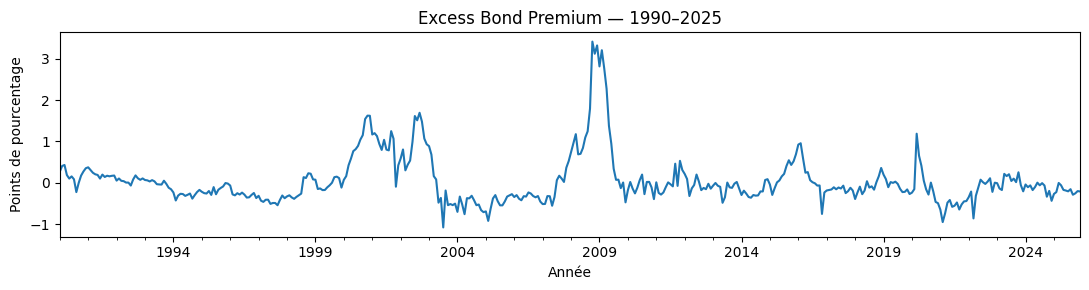

In [10]:
ax = ebp["ebp"].plot(figsize=(11, 3), title="Excess Bond Premium — 1990–2025")
ax.set_xlabel("Année")
ax.set_ylabel("Points de pourcentage")
plt.tight_layout()
plt.show()


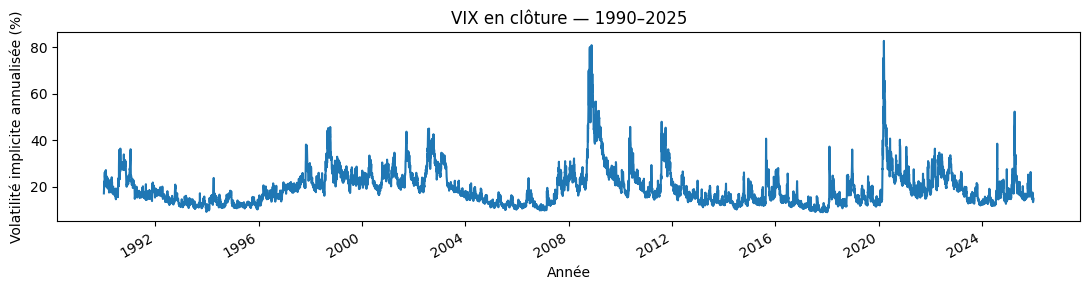

In [11]:
ax = vix["CLOSE"].plot(figsize=(11, 3), title="VIX en clôture — 1990–2025")
ax.set_xlabel("Année")
ax.set_ylabel("Volatilité implicite annualisée (%)")
plt.tight_layout()
plt.show()


Pour voir la volatilité réalisée, nous calculons l'écart-type des rendements
quotidiens à l'intérieur de chaque mois, puis nous l'annualisons avec `sqrt(252)`.
La multiplication par 100 sert à l'afficher en pourcentage.
`std(ddof=1)` utilise la convention d'écart-type échantillonnal.


Nombre de mois : 432
Jours de cotation par mois : 15 à 23


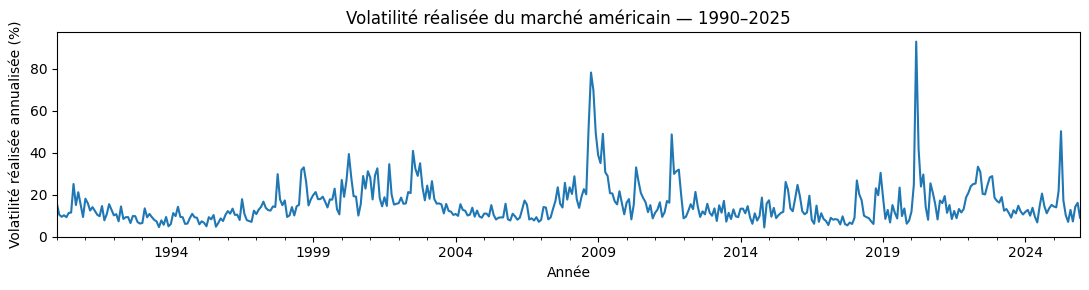

In [12]:
monthly_volatility = market["market_return"].resample("ME").std(ddof=1) * np.sqrt(252) * 100
trading_days = market["market_return"].resample("ME").count()
print("Nombre de mois :", len(monthly_volatility))
print("Jours de cotation par mois :", trading_days.min(), "à", trading_days.max())

ax = monthly_volatility.plot(figsize=(11, 3), title="Volatilité réalisée du marché américain — 1990–2025")
ax.set_xlabel("Année")
ax.set_ylabel("Volatilité réalisée annualisée (%)")
plt.tight_layout()
plt.show()


## 8. Mes observations

À compléter après avoir regardé les tableaux et graphiques :

1. Ce que contient chaque fichier et à quelle fréquence : …
2. Un épisode qui m'intéresse ou me surprend : …
3. Ce que le crédit pourrait apporter au-delà du VIX : …
4. Une limite que je dois signaler : …

## La suite après validation

Nous construirons les entrées disponibles à une date donnée et la volatilité du
mois suivant comme cible. Il faudra traiter le retard de publication de l'EBP,
puis séparer chronologiquement apprentissage, validation et test.
Les observations descriptives ci-dessus ne constituent pas une réponse prédictive.

**Assistance :** ce notebook initial a été préparé avec Codex (OpenAI).
Il reste à le relire, l'exécuter et comprendre chaque étape.
